# 09 · Weight Initialization, Normalization and Gradient Flow

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/anuxlab/deep-learning-systems/blob/main/notebooks/09-init-normalization/09_init_normalization.ipynb)
[![Run on GitHub Actions](https://img.shields.io/badge/run-GitHub%20Actions-2088FF?logo=githubactions&logoColor=white)](https://github.com/anuxlab/deep-learning-systems/actions/workflows/nb-09-init-normalization.yml)

| | |
|---|---|
| **Wiki chapter** | [Module 09](https://github.com/anuxlab/deep-learning-systems/wiki/Module-09) |
| **Level** | Intermediate |
| **Typical CPU runtime** | ~1 min (GitHub free runner, no GPU) |
| **Prerequisites** | Modules 05, 07 |

## What you will do

- Show why zero initialisation fails (symmetry) and why naive random scales vanish/explode with depth.
- Derive and verify Xavier/He initialisation by measuring activation and gradient variance across 50 layers.
- Implement BatchNorm, LayerNorm, RMSNorm and GroupNorm and match PyTorch (train *and* eval modes).
- Measure gradient flow in plain vs residual networks and train deep nets with/without normalisation.

> **How to use this notebook.** Read each markdown cell, *predict* what the next code cell will print, then run it.
> Every section ends with `check(...)` assertions: if one fails, something in your understanding (or the code) is off.
> Figures are saved to `figures/` and a machine-readable summary to `metrics.json` next to this notebook.

## 0 · Setup and reproducibility

We import shared helpers (`show` saves each figure to `figures/`, `check` asserts and logs, `timer` logs wall-clock time), fix all random seeds and print an environment report so every run is traceable (see the wiki's *Implementation and Research Standards*).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "_common"))   # shared helpers: notebooks/_common/dlsys.py
from dlsys import *                                       # np, plt, torch, seed_everything, show, check, timer, ...

SEED = seed_everything(42)
ENV = env_report()

16:30:39 | INFO | seed set to 42


          python: 3.12.16
        platform: Linux-7.0.0-1019-azure-x86_64-with-glibc2.43
       cpu_count: 4
          ram_gb: 15.6
           numpy: 2.5.5
           scipy: 1.18.1
         sklearn: 1.9.1
      matplotlib: 3.11.2
           torch: 2.15.0+cpu
  cuda_available: False
  github_actions: True
          run_id: 43908074938
          commit: 9d77658cc172e24db5f15aaa169fa5b35a9bd115


## 1 · Zero initialisation: the symmetry problem
If all weights in a layer are equal, all hidden units compute the same function and receive the **same gradient** — they stay identical forever. Random initialisation *breaks symmetry*. We train a tiny net from a constant init and check that the hidden units never differentiate.

In [2]:
torch.manual_seed(0)
X = torch.randn(64, 3); y = (X.sum(1, keepdim=True) > 0).float()
def make(const):
    m = nn.Sequential(nn.Linear(3, 4), nn.Tanh(), nn.Linear(4, 1))
    if const:
        for p in m.parameters(): nn.init.constant_(p, 0.3)
    return m
for const in [True, False]:
    m = make(const); o = torch.optim.SGD(m.parameters(), lr=.5)
    for _ in range(200): o.zero_grad(); F.binary_cross_entropy_with_logits(m(X), y).backward(); o.step()
    W = m[0].weight.detach(); spread = (W - W.mean(0, keepdim=True)).abs().max().item()
    print(f"{'constant' if const else 'random  '} init -> max difference between hidden units' weights after training: {spread:.2e}")
    if const: check(spread < 1e-6, "constant init: hidden units remain exact clones (symmetry never broken)")
    else: check(spread > 1e-2, "random init: units differentiate")

constant init -> max difference between hidden units' weights after training: 0.00e+00
  ✅ constant init: hidden units remain exact clones (symmetry never broken)
random   init -> max difference between hidden units' weights after training: 1.98e+00
  ✅ random init: units differentiate


## 2 · Variance analysis: why Xavier and He work
For $z=\sum_{i=1}^{n_{in}}w_ix_i$ with independent zero-mean $w$ and $x$: $\mathrm{Var}(z)=n_{in}\,\mathrm{Var}(w)\,\mathbb E[x^2]$. To keep the variance constant from layer to layer:

- **LeCun/Xavier (tanh, linear):** $\mathrm{Var}(w)=\frac1{n_{in}}$ (Glorot: $\frac{2}{n_{in}+n_{out}}$ to balance backward flow too).
- **He (ReLU):** ReLU zeroes half the inputs, $\mathbb E[x^2]=\tfrac12\mathrm{Var}(z)$, hence $\mathrm{Var}(w)=\frac2{n_{in}}$.

We push random data through 50-layer networks and record the standard deviation of activations at each layer for several scales.

16:30:42 | INFO | figure saved -> figures/init_forward_variance.png


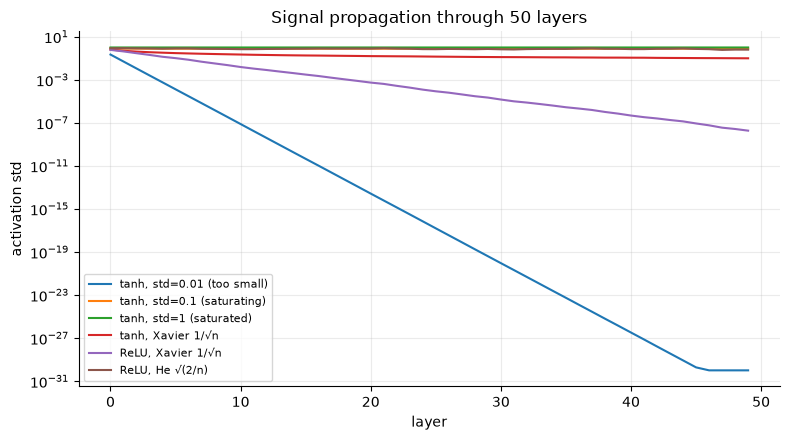

tanh, std=0.01 (too small)   std after layer 50: 4.910e-33
tanh, std=0.1 (saturating)   std after layer 50: 7.689e-01
tanh, std=1 (saturated)      std after layer 50: 9.818e-01
tanh, Xavier 1/√n            std after layer 50: 9.698e-02
ReLU, Xavier 1/√n            std after layer 50: 1.845e-08
ReLU, He √(2/n)              std after layer 50: 6.189e-01
  ✅ tiny init -> signal vanishes
(tanh is bounded, so 'too big' shows up as saturation at ±1 — where tanh' ≈ 0 and gradients die — rather than as overflow.)
  ✅ Xavier keeps tanh activations alive at depth 50
  ✅ He keeps ReLU stable; Xavier's 1/√n halves variance each layer


In [3]:
def forward_stats(act, std_fn, depth=50, width=512, seed=0):
    g = torch.Generator().manual_seed(seed); x = torch.randn(256, width, generator=g); stds = []
    for _ in range(depth):
        W = torch.randn(width, width, generator=g) * std_fn(width); x = act(x @ W); stds.append(x.std().item())
    return np.array(stds)
cases = {
 "tanh, std=0.01 (too small)": (torch.tanh, lambda n: .01), "tanh, std=0.1 (saturating)": (torch.tanh, lambda n: .1), "tanh, std=1 (saturated)": (torch.tanh, lambda n: 1.0),
 "tanh, Xavier 1/√n": (torch.tanh, lambda n: n ** -.5),
 "ReLU, Xavier 1/√n": (torch.relu, lambda n: n ** -.5), "ReLU, He √(2/n)": (torch.relu, lambda n: (2 / n) ** .5)}
fig, ax = plt.subplots(figsize=(8, 4.5)); S = {}
for k, (a, s) in cases.items(): S[k] = forward_stats(a, s); ax.semilogy(np.maximum(S[k], 1e-30), label=k)
ax.set_xlabel("layer"); ax.set_ylabel("activation std"); ax.legend(fontsize=8); ax.set_title("Signal propagation through 50 layers"); show("init_forward_variance")
for k, v in S.items(): print(f"{k:28s} std after layer 50: {v[-1]:.3e}")
check(S["tanh, std=0.01 (too small)"][-1] < 1e-10, "tiny init -> signal vanishes")
print("(tanh is bounded, so 'too big' shows up as saturation at ±1 — where tanh' ≈ 0 and gradients die — rather than as overflow.)")
check(S["tanh, Xavier 1/√n"][-1] > .05, "Xavier keeps tanh activations alive at depth 50")
check(S["ReLU, He √(2/n)"][-1] > .3 and S["ReLU, Xavier 1/√n"][-1] < S["ReLU, He √(2/n)"][-1] / 100, "He keeps ReLU stable; Xavier's 1/√n halves variance each layer")
METRICS["final_std"] = {k: float(v[-1]) for k, v in S.items()}

### Backward gradient flow
The same analysis for gradients: with `PyTorch` autograd we measure $\|\partial\mathcal L/\partial h_l\|$ per layer in a 30-layer ReLU network under bad vs He initialisation.

16:30:42 | INFO | figure saved -> figures/init_backward_grad.png


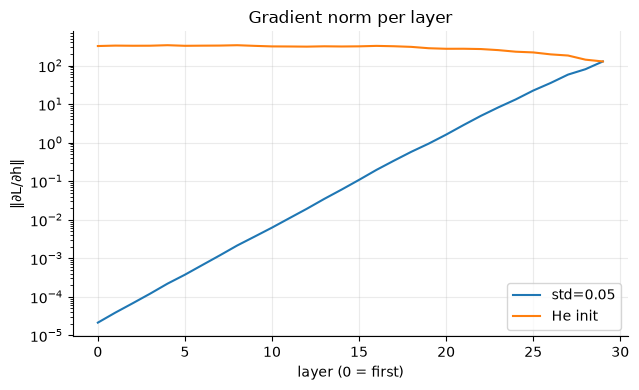

  ✅ bad init: gradient vanishes towards the input layers
  ✅ He init: gradient norm stays within two orders of magnitude


In [4]:
def grad_profile(std_fn, depth=30, width=256, seed=0):
    g = torch.Generator().manual_seed(seed); x = torch.randn(64, width, generator=g).requires_grad_(); hs = []
    for _ in range(depth):
        W = torch.randn(width, width, generator=g) * std_fn(width); x = torch.relu(x @ W); x.retain_grad(); hs.append(x)
    x.sum().backward(); return np.array([h.grad.norm().item() for h in hs])
bad, good = grad_profile(lambda n: .05), grad_profile(lambda n: (2 / n) ** .5)
plt.semilogy(bad, label="std=0.05"); plt.semilogy(good, label="He init"); plt.xlabel("layer (0 = first)"); plt.ylabel("‖∂L/∂h‖"); plt.legend(); plt.title("Gradient norm per layer"); show("init_backward_grad")
check(bad[0] < bad[-1] * 1e-6, "bad init: gradient vanishes towards the input layers")
check(good[0] / good[-1] < 100 and good[0] / good[-1] > .01, "He init: gradient norm stays within two orders of magnitude")

## 3 · BatchNorm from scratch
For a mini-batch, per feature: $\hat x=\frac{x-\mu_B}{\sqrt{\sigma_B^2+\epsilon}}$, $y=\gamma\hat x+\beta$. In **training** it uses batch statistics and updates running averages $\mu_{run}\leftarrow(1-m)\mu_{run}+m\mu_B$; at **evaluation** it uses the running statistics (so the output no longer depends on other samples in the batch). The unbiased variance is used for the running estimate, the biased one for normalising. Check against `nn.BatchNorm1d`.

In [5]:
class MyBN:
    def __init__(s, d, eps=1e-5, mom=.1): s.g, s.b, s.eps, s.mom = np.ones(d), np.zeros(d), eps, mom; s.rm, s.rv, s.training = np.zeros(d), np.ones(d), True
    def __call__(s, x):
        if s.training:
            mu, var = x.mean(0), x.var(0)                       # biased var for normalisation
            n = len(x); s.rm = (1 - s.mom) * s.rm + s.mom * mu; s.rv = (1 - s.mom) * s.rv + s.mom * var * n / (n - 1)
        else: mu, var = s.rm, s.rv
        return s.g * (x - mu) / np.sqrt(var + s.eps) + s.b
r = np.random.default_rng(0); bn, tbn = MyBN(5), nn.BatchNorm1d(5, dtype=torch.float64)
for it in range(5):
    xb = r.normal(3 * it, 2, size=(32, 5)); a = bn(xb); b = tbn(torch.tensor(xb)).detach().numpy()
    check(np.allclose(a, b, atol=1e-10), f"train-mode output matches torch (iteration {it})")
check(np.allclose(bn.rm, tbn.running_mean.numpy()) and np.allclose(bn.rv, tbn.running_var.numpy()), "running mean/var match torch")
bn.training = False; tbn.eval(); xe = r.normal(size=(7, 5))
check(np.allclose(bn(xe), tbn(torch.tensor(xe)).detach().numpy(), atol=1e-10), "eval-mode output matches torch (uses running stats)")
y_train = MyBN(5)(r.normal(5, 3, size=(256, 5))); check(abs(y_train.mean()) < 1e-9 and abs(y_train.std() - 1) < 1e-3, "BN output has mean 0 and std 1 per feature")

  ✅ train-mode output matches torch (iteration 0)
  ✅ train-mode output matches torch (iteration 1)
  ✅ train-mode output matches torch (iteration 2)
  ✅ train-mode output matches torch (iteration 3)
  ✅ train-mode output matches torch (iteration 4)
  ✅ running mean/var match torch
  ✅ eval-mode output matches torch (uses running stats)
  ✅ BN output has mean 0 and std 1 per feature


## 4 · Normalisation axes: Batch / Layer / Group / RMS
For a tensor $(N,C,H,W)$ the methods differ only in **which axes are averaged**:

| method | statistics over | depends on batch? |
|---|---|---|
| BatchNorm | $(N,H,W)$ per channel | yes |
| LayerNorm | $(C,H,W)$ per sample | no |
| InstanceNorm | $(H,W)$ per sample & channel | no |
| GroupNorm | $(C/G,H,W)$ per sample & group | no |
| RMSNorm | like LayerNorm but only divides by $\sqrt{\mathbb E x^2}$ (no centring) | no |

We implement them through one helper and compare to torch; then show BN's weakness at tiny batch sizes.

  ✅ BatchNorm axes (N,H,W)
  ✅ LayerNorm axes (C,H,W)
  ✅ InstanceNorm axes (H,W)
  ✅ GroupNorm (3 groups)
  ✅ RMSNorm matches torch.nn.RMSNorm


16:30:43 | INFO | figure saved -> figures/bn_batch_noise.png


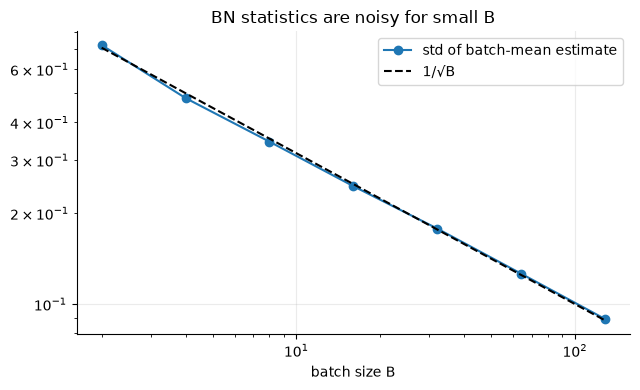

  ✅ batch size 2 gives ≫ noisier statistics than 128 — why GroupNorm/LayerNorm are used for small batches


In [6]:
def norm_axes(x, axes, eps=1e-5): mu = x.mean(axes, keepdims=True); v = x.var(axes, keepdims=True); return (x - mu) / np.sqrt(v + eps)
xr = np.random.default_rng(1).normal(2, 3, size=(8, 6, 5, 5))                     # (N,C,H,W)
xt = torch.tensor(xr)
check(np.allclose(norm_axes(xr, (0, 2, 3)), F.batch_norm(xt, None, None, training=True).numpy(), atol=1e-6), "BatchNorm axes (N,H,W)")
check(np.allclose(norm_axes(xr, (1, 2, 3)), F.layer_norm(xt, xt.shape[1:]).numpy(), atol=1e-6), "LayerNorm axes (C,H,W)")
check(np.allclose(norm_axes(xr, (2, 3)), F.instance_norm(xt).numpy(), atol=1e-6), "InstanceNorm axes (H,W)")
g = xr.reshape(8, 3, 2, 5, 5); check(np.allclose(norm_axes(g, (2, 3, 4)).reshape(xr.shape), F.group_norm(xt, 3).numpy(), atol=1e-6), "GroupNorm (3 groups)")
rms = lambda x, eps=1e-6: x / np.sqrt((x ** 2).mean(-1, keepdims=True) + eps)
xf = np.random.default_rng(2).normal(size=(4, 16)); check(np.allclose(rms(xf), nn.RMSNorm(16, eps=1e-6, elementwise_affine=False)(torch.tensor(xf)).numpy(), atol=1e-6), "RMSNorm matches torch.nn.RMSNorm")

# BN noise at small batch sizes: variability of the batch-mean estimate ∝ 1/sqrt(B)
pop = np.random.default_rng(3).normal(0, 1, size=100000); Bs = [2, 4, 8, 16, 32, 64, 128]
sd = [np.std([np.random.default_rng(i).choice(pop, B).mean() for i in range(400)]) for B in Bs]
plt.loglog(Bs, sd, "o-", label="std of batch-mean estimate"); plt.loglog(Bs, 1 / np.sqrt(Bs), "k--", label="1/√B"); plt.xlabel("batch size B"); plt.legend(); plt.title("BN statistics are noisy for small B"); show("bn_batch_noise")
check(sd[0] > 5 * sd[-1], "batch size 2 gives ≫ noisier statistics than 128 — why GroupNorm/LayerNorm are used for small batches")

## 5 · Residual connections: an identity path for gradients
A residual block computes $h_{l+1}=h_l+F(h_l)$, so $\partial h_{L}/\partial h_l=\prod(I+\partial F/\partial h)$ always contains an **identity term** — the gradient can't vanish even if $F$'s Jacobians are tiny. We compare per-layer gradient norms of a 40-layer plain tanh network vs the same network with skip connections.

16:30:43 | INFO | figure saved -> figures/residual_gradient_flow.png


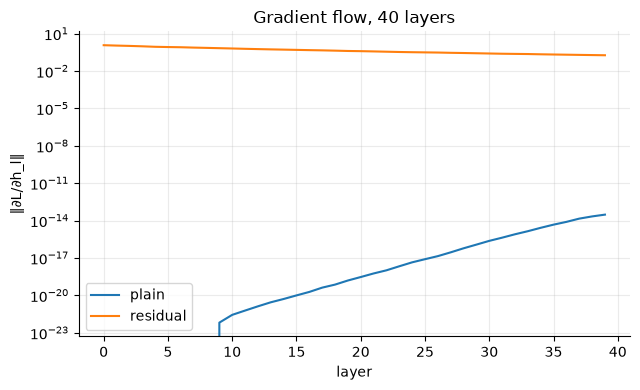

plain: first/last grad ratio = 0.00e+00;  residual: 6.41e+00
  ✅ plain net's gradient vanishes toward the input; residual's does not


In [7]:
def deep_grads(residual, depth=40, width=64, seed=0):
    torch.manual_seed(seed); layers = [nn.Linear(width, width) for _ in range(depth)]
    for l in layers: nn.init.normal_(l.weight, 0, .5 / np.sqrt(width)); nn.init.zeros_(l.bias)
    h = torch.randn(32, width); hs = []
    for l in layers:
        out = torch.tanh(l(h)); h = h + out if residual else out; h.retain_grad(); hs.append(h)
    h.pow(2).mean().backward(); return np.array([a.grad.norm().item() for a in hs])
gp, gr = deep_grads(False), deep_grads(True)
plt.semilogy(gp, label="plain"); plt.semilogy(gr, label="residual"); plt.xlabel("layer"); plt.ylabel("‖∂L/∂h_l‖"); plt.legend(); plt.title("Gradient flow, 40 layers"); show("residual_gradient_flow")
print(f"plain: first/last grad ratio = {gp[0]/gp[-1]:.2e};  residual: {gr[0]/gr[-1]:.2e}")
check(gp[0] / gp[-1] < 1e-3 and gr[0] / gr[-1] > .1, "plain net's gradient vanishes toward the input; residual's does not")

## 6 · Training a 20-layer MLP: plain vs BatchNorm vs residual+LayerNorm
Everything above, in a real (small) training run on the digits dataset. Identical optimiser (Adam) and depth; only the architecture changes. We use a *mildly bad* initialisation (std=0.05) to expose the differences.

plain        params= 88,010  final train loss=2.3012  test acc=0.078


batchnorm    params= 90,570  final train loss=0.0702  test acc=0.970


residual+LN  params= 90,570  final train loss=0.0013  test acc=0.974


16:30:53 | INFO | figure saved -> figures/deep_mlp_training.png


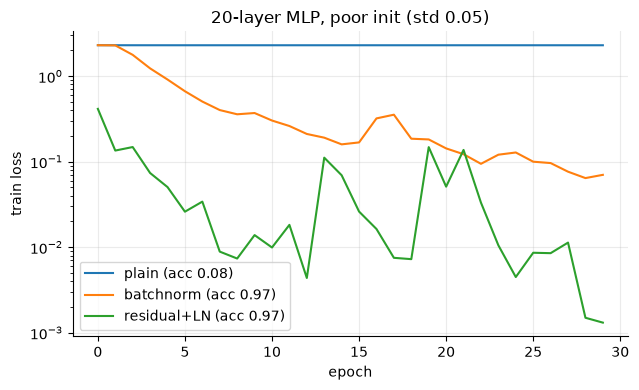

  ✅ residual+LayerNorm trains far better than the plain deep net
  ✅ BatchNorm also rescues the plain network


In [8]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
D = load_digits(); Xd = torch.tensor(D.data / 16., dtype=torch.float32); yd = torch.tensor(D.target)
idx = np.random.default_rng(0).permutation(len(Xd)); tr, te = idx[:1300], idx[1300:]
class Res(nn.Module):
    def __init__(s, w): super().__init__(); s.n = nn.LayerNorm(w); s.f = nn.Sequential(nn.Linear(w, w), nn.ReLU())
    def forward(s, x): return x + s.f(s.n(x))
def build(kind, depth=20, w=64):
    L = [nn.Linear(64, w), nn.ReLU()]
    for _ in range(depth):
        if kind == "plain": L += [nn.Linear(w, w), nn.ReLU()]
        elif kind == "batchnorm": L += [nn.Linear(w, w), nn.BatchNorm1d(w), nn.ReLU()]
        else: L += [Res(w)]
    m = nn.Sequential(*L, nn.Linear(w, 10))
    for mod in m.modules():
        if isinstance(mod, nn.Linear): nn.init.normal_(mod.weight, 0, .05)
    return m
res = {}
for kind in ["plain", "batchnorm", "residual+LN"]:
    torch.manual_seed(0); m = build(kind); o = torch.optim.Adam(m.parameters(), 1e-3); curve = []
    for ep in range(30):
        m.train(); perm = torch.tensor(tr)[torch.randperm(len(tr))]
        for s in range(0, len(perm), 64):
            b = perm[s:s + 64]; o.zero_grad(); l = F.cross_entropy(m(Xd[b]), yd[b]); l.backward(); o.step()
        m.eval()
        with torch.no_grad(): curve.append(F.cross_entropy(m(Xd[tr]), yd[tr]).item())
    with torch.no_grad(): acc = (m(Xd[te]).argmax(1) == yd[te]).float().mean().item()
    res[kind] = (curve, acc); print(f"{kind:12s} params={count_params(m):7,d}  final train loss={curve[-1]:.4f}  test acc={acc:.3f}")
for k, (c, a) in res.items(): plt.semilogy(c, label=f"{k} (acc {a:.2f})")
plt.xlabel("epoch"); plt.ylabel("train loss"); plt.legend(); plt.title("20-layer MLP, poor init (std 0.05)"); show("deep_mlp_training")
check(res["residual+LN"][1] > res["plain"][1] + .1, "residual+LayerNorm trains far better than the plain deep net")
check(res["batchnorm"][1] > res["plain"][1], "BatchNorm also rescues the plain network")
METRICS["deep_mlp_test_acc"] = {k: v[1] for k, v in res.items()}

In [9]:
save_metrics("09", METRICS)
log.info('notebook 09 finished OK')

16:30:54 | INFO | metrics saved -> metrics.json


16:30:54 | INFO | notebook 09 finished OK


## Wrap-up

## Exercises (do these next)

1. Replace the Gaussian init with `nn.init.kaiming_normal_` in section 6; does the plain network now train?
2. Add a *fixup*-style zero-initialised last layer in each residual branch and compare gradient flow at step 0.
3. Verify that BatchNorm followed by a bias-free Linear layer makes the previous layer's bias redundant.

## Where to read more

- Wiki chapter: [Module 09](https://github.com/anuxlab/deep-learning-systems/wiki/Module-09) (derivations, worked example, Q&A).
- Glorot & Bengio (2010); He et al. (2015); Ioffe & Szegedy (2015) BatchNorm; Ba et al. (2016) LayerNorm; Wu & He (2018) GroupNorm; Zhang & Sennrich (2019) RMSNorm; He et al. (2016) ResNet.